# Three-channel walkthrough: DAPI and GFP-DnaN objects

Each field contains phase contrast (`C1`), DAPI (`C2`, DNA/nucleoid), and
GFP-DnaN (`C3`, replication-associated puncta). We inspect masks and meshes,
detect intracellular objects, and extract one feature-table row per cell.


Run the cells from top to bottom. Supplied masks are reused by default;
fresh segmentation and SVM curation are optional. You can also filter the
resulting feature table afterwards, without using an SVM.

The setup copies the dataset from `SOURCE_DIR` to a fresh `RUN_DIR` under
`~/bactoscoop_runs/`. All new masks, meshes, and tables are written to that
working copy. Change settings in the cell that uses them. See the
[README](../README.md) for installation.

In [1]:
from datetime import datetime
from pathlib import Path
import os
import shutil

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import bactoscoop
import bactoscoop.plot as bplt

%matplotlib inline

In [2]:
# Set SOURCE_DIR to your extracted 3_channel_example folder if it is elsewhere.
SOURCE_DIR = None
if SOURCE_DIR is None:
    examples_dir = os.environ.get("BACTOSCOOP_EXAMPLES_DIR")
    candidates = ([Path(examples_dir)] if examples_dir else
                  [folder for base in (Path.cwd(), *Path.cwd().parents)
                   for folder in (base / "examples", base)])
    SOURCE_DIR = next((base / "3_channel_example" for base in candidates
                       if (base / "3_channel_example").is_dir()), None)
if SOURCE_DIR is None:
    raise FileNotFoundError("Set SOURCE_DIR to the extracted 3_channel_example folder.")
SOURCE_DIR = Path(SOURCE_DIR).expanduser().resolve()
RUN_DIR = (Path.home() / "bactoscoop_runs" /
           datetime.now().strftime("%Y%m%d_%H%M%S_%f") / "3_channel_example")
shutil.copytree(SOURCE_DIR, RUN_DIR)

PHASE_CHANNEL = "C1"
CHANNEL_LABELS = {'C1': 'Phase contrast', 'C2': 'DAPI', 'C3': 'GFP-DnaN'}
FIELD_IDS = bplt.list_field_ids(RUN_DIR, phase_channel=PHASE_CHANNEL)
print("Source dataset:", SOURCE_DIR)
print("Working copy and outputs:", RUN_DIR)
print("Fields:", FIELD_IDS)

Source dataset: C:\Users\Bart\bactoscoop\examples\3_channel_example
Working copy and outputs: C:\Users\Nikon\bactoscoop_runs\20261110_130411_948518\3_channel_example
Fields: ['TL4_SGL711_M9glu_12H_XY5', 'TL4_SGL711_M9glu_12H_XY6']


## 1. Inspect the input channels

A field is identified by the shared filename before `_C1`, `_C2`, and so on.
Display contrast is adjusted per panel; measurements use the original image
values. Choose a field and crop size below.

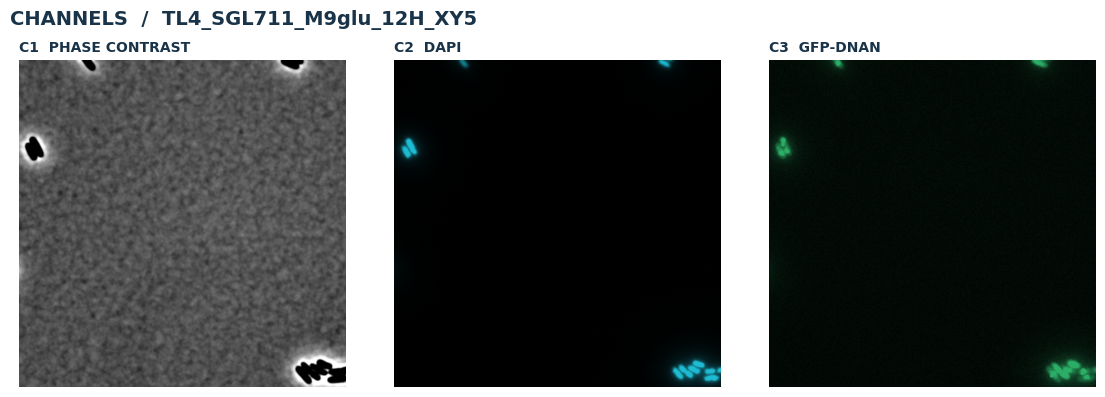

In [3]:
OVERVIEW_FIELD = FIELD_IDS[0]
OVERVIEW_CROP_PX = 650
fig = bplt.plot_field_channels(
    RUN_DIR, OVERVIEW_FIELD, CHANNEL_LABELS, crop_size=OVERVIEW_CROP_PX,
)
display(fig)
plt.close(fig)

## 2. Load masks or run segmentation

Set the pixel size to your microscope calibration in micrometres per pixel.
Leave `RUN_SEGMENTATION=False` to load the supplied masks. Set it to `True`
to run Omnipose on C1; segmentation uses a GPU when available, otherwise CPU.
`mask_thresh` adjusts mask boundaries and `minsize` removes small segments.
Other tools' masks also work: use same-size 2D integer TIFFs with background
0 and consecutive cell labels 1 through N.

In [4]:
PIXEL_SIZE_UM = 0.065
RUN_SEGMENTATION = False

ic = bactoscoop.ImageCollection(str(RUN_DIR), px=PIXEL_SIZE_UM)
ic.load_phase_images(phase_channel=PHASE_CHANNEL)
if RUN_SEGMENTATION:
    ok = ic.segment_images(
        mask_thresh=1, minsize=100, n=range(len(ic.images)),
        model_name="bact_phase_omni",
    )
    if not ok:
        raise RuntimeError(ic.processing_summary())
ic.create_image_objects(phase_channel=PHASE_CHANNEL)

### Review the masks

Rerun only the next cell to inspect another field, label, or crop. A
700-pixel crop shows several cells; around 150–250 pixels gives a closer
view. Both panels show the same crop, with mask outlines added on the right.

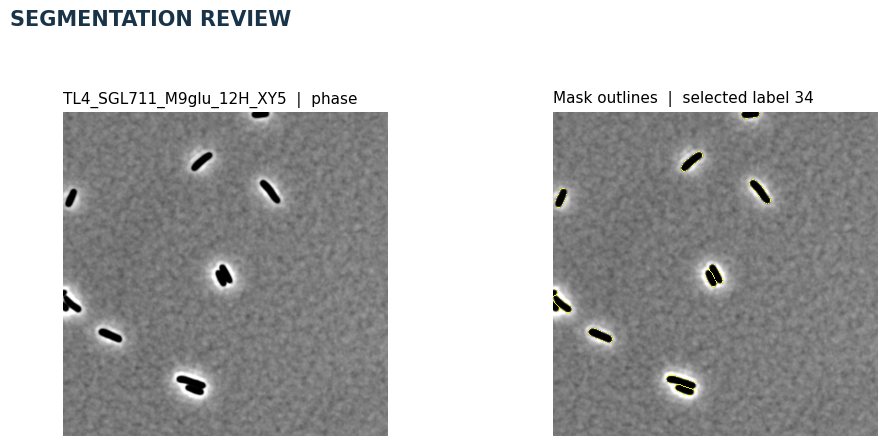

In [5]:
SEGMENTATION_FIELD = FIELD_IDS[0]
SEGMENTATION_LABEL = None  # Set an integer label to centre on that cell.
SEGMENTATION_CENTER = None  # Optional (row, column) when label is None.
SEGMENTATION_CROP_PX = 700

review_image = next(image for image in ic.image_objects
                    if image.image_name.rsplit("_", 1)[0] == SEGMENTATION_FIELD)
fig = bplt.plot_segmentation_review(
    [review_image], crop_size=SEGMENTATION_CROP_PX,
    mask_label=SEGMENTATION_LABEL, center=SEGMENTATION_CENTER,
)
display(fig)
plt.close(fig)

## 3. Build and inspect meshes

Each mask becomes a contour, paired mesh sides, and a midline. Join cell
masks when their nearest poles are at most `join_thresh` pixels apart.
`split_thresh` controls splitting at constrictions; `smoothing` controls
contour smoothing; `CD_width=True` uses width to assess constriction.

The default builds and saves `3_channel_example_meshdata.pkl` in `RUN_DIR`.
Set `LOAD_SAVED_MESHES=True` to load the file currently in `RUN_DIR` instead.
To resume an earlier analysis, set `SOURCE_DIR` to that run's folder before setup.
Only reload meshes that match the current images and masks.

In [6]:
LOAD_SAVED_MESHES = False
if LOAD_SAVED_MESHES:
    ic.batch_load_mesh("3_channel_example_meshdata.pkl", phase_channel=PHASE_CHANNEL)
else:
    ic.batch_process_mesh(
        phase_channel=PHASE_CHANNEL, join_thresh=4, split_thresh=0.5,
        CD_width=False, smoothing=0.1, save_data=True,
    )
print("Cells with meshes:", sum(len(image.cells) for image in ic.image_objects))

Cell objects are created from processed meshes. 147 Cell objects are created.


Cell objects are created from processed meshes. 182 Cell objects are created.
Cells with meshes: 329


### Inspect the cell coordinate system

Choose a field and cell ID directly below. Set the ID to `None` for an
automatically selected representative cell. The plot shows phase contrast,
the contour, mesh, and midline.

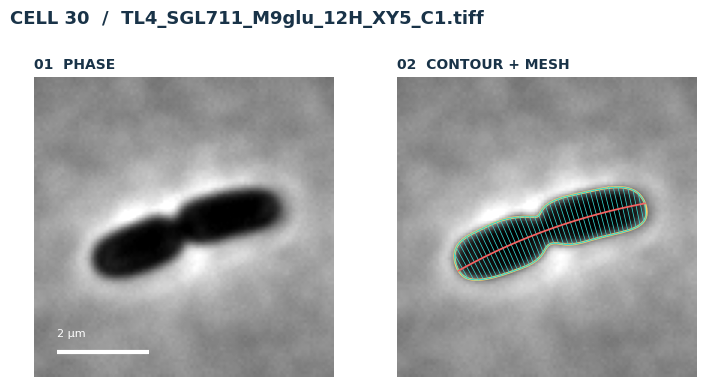

In [7]:
MESH_FIELD = FIELD_IDS[0]
MESH_CELL_ID = 30
MESH_WINDOW_PX = 100
mesh_image, mesh_cell_id = bplt.select_example_cell(
    ic.image_objects, field_id=MESH_FIELD, cell_id=MESH_CELL_ID,
)
fig = bplt.plot_cell_gallery(
    mesh_image, mesh_cell_id, channel=None, window_px=MESH_WINDOW_PX,
)
display(fig)
plt.close(fig)

## 4. Optional: curate meshes with an SVM

`RUN_CURATION=True` applies the example's `DnaN_Timecourse.pkl` model. Green contours
are retained and red contours are rejected. This changes the cell population
before feature extraction and saves `3_channel_example_curated_meshdata.pkl`.

Set the switch to `False` to continue without an SVM or model file. You can
filter the feature table in step 8 instead. Cells rejected here will not
receive later measurements. Inspect predictions before applying the supplied
model to other data, and only load trusted pickle files. To switch curation off
after applying it, rerun from step 3 to restore the uncurated meshes first.


Number of removed rows: 0


SVM curation: 329 to 128 cells


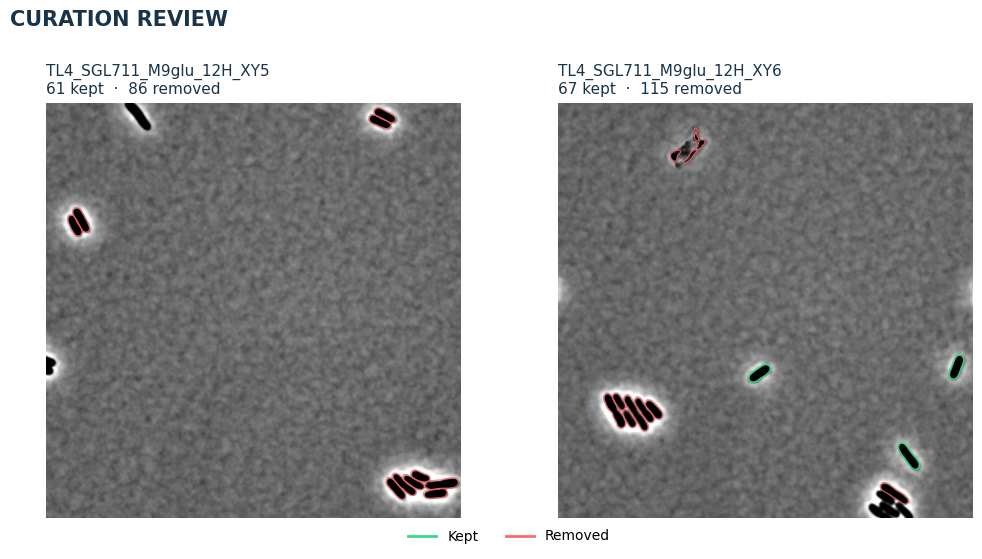

In [8]:
RUN_CURATION = True
MODEL_PATH = RUN_DIR / "DnaN_Timecourse.pkl"

if RUN_CURATION:
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(MODEL_PATH)
    before_contours = bplt.snapshot_cell_contours(ic.image_objects)
    before_count = sum(len(image.cells) for image in ic.image_objects)
    ic.curate_dataset(str(MODEL_PATH), control=False, save_curated_data=True)
    after_count = sum(len(image.cells) for image in ic.image_objects)
    print(f"SVM curation: {before_count:,} to {after_count:,} cells")
    fig = bplt.plot_curation_review(before_contours, ic.image_objects)
    display(fig)
    plt.close(fig)
else:
    print("SVM curation skipped; continuing with all reconstructed cells.")

## 5. Detect and review objects

Detect DAPI regions in C2 and GFP-DnaN puncta in C3. Both channels stay in
their original coordinates (`align=False`). We use the C3 detections for
object features in step 6; C2 is also used for intensity profiles.
`log_sigma` controls image filtering, `kernel_width` affects candidate-object
dilation, and the overlap limits control which candidates are accepted.
The count below sums individual contours, rather than cell/channel rows.

In [9]:
detections = ic.batch_detect_objects(
    channels=["C2", "C3"], reset_channels=True, align=False,
    smoothing=0.1, log_sigma=3, kernel_width=3,
    min_overlap_ratio=0.001, max_external_ratio=0.5,
)
object_counts = (detections.assign(object_count=detections["object_contours"].map(len))
                 .groupby("channel")["object_count"].sum())
print("Detected objects per channel:")
display(object_counts)

Detected objects per channel:


channel
C2    139
C3    174
Name: object_count, dtype: int64

### Inspect a detected cell

Select the field, cell, and crop below. If curation removed a chosen cell,
select a retained ID or set it to `None`. The outlines show detected signal
regions. Rerunning this plot does not repeat detection.

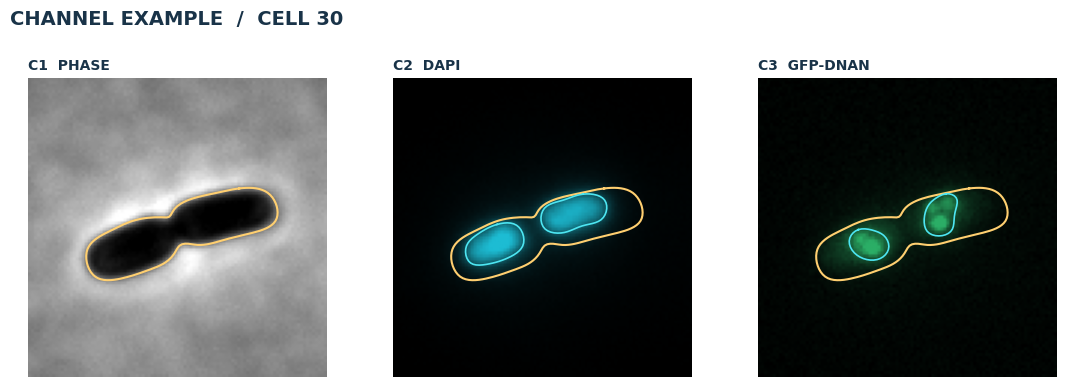

In [10]:
OBJECT_FIELD = FIELD_IDS[0]
OBJECT_CELL_ID = 30
OBJECT_WINDOW_PX = 100
object_image, object_cell_id = bplt.select_example_cell(
    ic.image_objects, field_id=OBJECT_FIELD, cell_id=OBJECT_CELL_ID,
)

fig = bplt.plot_signal_gallery(
    object_image, object_cell_id,
    channel_labels={"C2": "DAPI", "C3": "GFP-DnaN"},
    window_px=OBJECT_WINDOW_PX, show_objects=True,
)
display(fig)
plt.close(fig)

## 6. Extract features

`channel_method_pairs` assigns feature methods to channels. `morphological`
measures cell geometry, `profiling` measures channel intensity profiles, and
`objects` summarizes C3 puncta. `max_mesh_size` excludes cells with more than
that many mesh rows. The merged table has one row per cell, with channel
prefixes such as `C3_` on signal features.

`C3_NC_ratio` is the summed area of detected C3 objects divided by cell area.
It is a within-cell area fraction, but detection still depends on signal
quality and the chosen detection parameters.

In [11]:
channel_method_pairs = [
    ([None], "morphological"),
    (["C2", "C3"], "profiling"),
    (["C3"], "objects"),
]
ic.batch_calculate_features(
    channel_method_pairs, all_data=False, reset=True, max_mesh_size=1000,
)
features = ic.merge_dataframes(discard_morphological_nan=True)
print(f"{len(features):,} cells × {len(features.columns)} columns")
display(features[["image_name", "cell_id", "cell_length", "cell_width", "cell_area"]].head())

128 cells × 188 columns


,image_name,cell_id,cell_length,cell_width,cell_area
0,TL4_SGL711_M9glu_12H_XY5_C1.tiff,0,2.550915,1.038571,2.227059
1,TL4_SGL711_M9glu_12H_XY5_C1.tiff,1,4.888522,1.112940,4.710786
2,TL4_SGL711_M9glu_12H_XY5_C1.tiff,2,3.009912,1.072538,2.827967
3,TL4_SGL711_M9glu_12H_XY5_C1.tiff,5,3.217199,1.029288,2.934590
4,TL4_SGL711_M9glu_12H_XY5_C1.tiff,13,2.799789,1.141890,2.715358


## 7. Inspect feature distributions

Start with cell length, width, projected area, and detected-object count.
These histograms show the measurements and their spread in this dataset;
they are not universal acceptance ranges. Missing values are omitted from
each plot and should not be interpreted as zero objects.

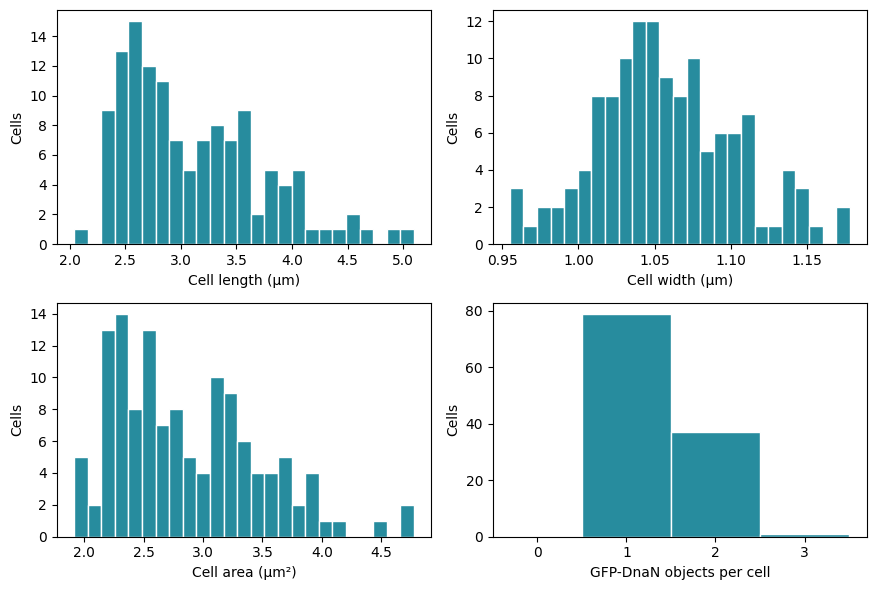

In [12]:
from matplotlib.ticker import MaxNLocator

HISTOGRAM_BINS = 25
plot_features = [
    ("cell_length", "Cell length (µm)"),
    ("cell_width", "Cell width (µm)"),
    ("cell_area", "Cell area (µm²)"),
    ("C3_object_number", "GFP-DnaN objects per cell"),
]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (column, label) in zip(axes.flat, plot_features):
    values = features[column].dropna()
    bins = ([i - 0.5 for i in range(int(values.max()) + 2)]
            if column.endswith("object_number") and not values.empty else HISTOGRAM_BINS)
    ax.hist(values, bins=bins, color="#278C9E", edgecolor="white")
    ax.set(xlabel=label, ylabel="Cells")
    if column.endswith("object_number"):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlim(left=-0.5)
fig.tight_layout()
display(fig)
plt.close(fig)

## 8. Optional: filter the resulting table

You can select cells using their measured features, whether or not you ran
SVM curation. The length limits below are illustrative: inspect your images
and histograms before choosing limits for your data. The original `features`
table stays available; this step creates a separate `filtered_features`
table. Earlier exclusions cannot be recovered from this table.

In [13]:
APPLY_FEATURE_FILTER = False
MIN_CELL_LENGTH_UM = 1.0
MAX_CELL_LENGTH_UM = 10.0

if APPLY_FEATURE_FILTER:
    keep = features["cell_length"].between(MIN_CELL_LENGTH_UM, MAX_CELL_LENGTH_UM)
    filtered_features = features.loc[keep].copy()
else:
    filtered_features = features.copy()
print(f"Feature-table selection: {len(features):,} to {len(filtered_features):,} cells")

Feature-table selection: 128 to 128 cells


## 9. Save features

Save the full merged table as `3_channel_example_features.parquet` and
`3_channel_example_features.pkl` in `RUN_DIR`. When feature filtering is enabled,
save that selection separately as `3_channel_example_filtered_features.parquet`.


In [14]:
ic.dataframe_to_parquet()
pickle_path = ic.dataframe_to_pkl()
if APPLY_FEATURE_FILTER:
    filtered_features.to_parquet(
        RUN_DIR / "3_channel_example_filtered_features.parquet", index=False,
    )
saved = pd.read_parquet(RUN_DIR / "3_channel_example_features.parquet")
print("Saved full table:", len(saved), "rows")
print("Outputs:", RUN_DIR)


Saved full table: 128 rows
Outputs: C:\Users\Nikon\bactoscoop_runs\20261110_130411_948518\3_channel_example
